In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Simulação dos dados que você possui (Fato e Dimensão)
df_vendas = pd.DataFrame({
    'sku': ['P01', 'P02', 'P01', 'P03', 'P02'],
    'quantidade': [2, 5, 1, 10, 3]
})

df_produtos = pd.DataFrame({
    'sku': ['P01', 'P02', 'P03'],
    'preco_unitario': [50.00, 20.00, 15.00]
})

# 2. Fazendo o cruzamento (Join/Merge)
df_analytics = pd.merge(df_vendas, df_produtos, on='sku')

# 3. Criando a variável dependente (o que queremos prever)
df_analytics['faturamento'] = df_analytics['quantidade'] * df_analytics['preco_unitario']

print(df_analytics[['quantidade', 'faturamento']])

   quantidade  faturamento
0           2        100.0
1           5        100.0
2           1         50.0
3          10        150.0
4           3         60.0


In [2]:
# Definindo as variáveis
X = df_analytics[['quantidade']] # Feature (Tamanho do pedido)
y = df_analytics['faturamento']  # Target (O que queremos prever)

# Inicializando e treinando o modelo (A mágica acontece aqui)
modelo = LinearRegression()
modelo.fit(X, y)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [4]:
# Queremos prever o faturamento para um pedido de 8 unidades
nova_quantidade = np.array([[8]])

predicao = modelo.predict(nova_quantidade)

print(f"Para um pedido de 8 unidades, o faturamento estimado é de: R$ {predicao[0]:.2f}")

Para um pedido de 8 unidades, o faturamento estimado é de: R$ 129.25


C:\Users\Hashtag\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


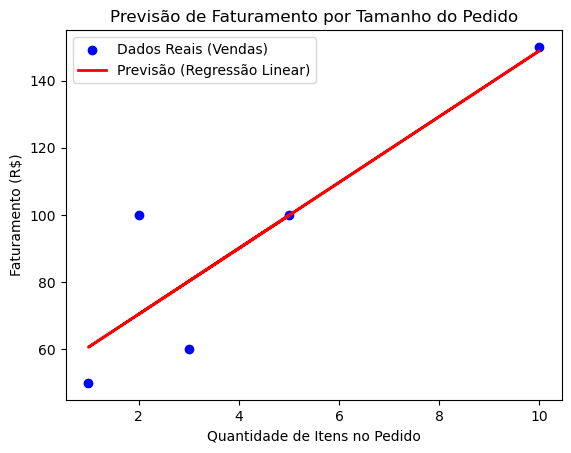

In [5]:
plt.scatter(X, y, color='blue', label='Dados Reais (Vendas)')
plt.plot(X, modelo.predict(X), color='red', linewidth=2, label='Previsão (Regressão Linear)')
plt.title('Previsão de Faturamento por Tamanho do Pedido')
plt.xlabel('Quantidade de Itens no Pedido')
plt.ylabel('Faturamento (R$)')
plt.legend()
plt.show()